In [21]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
import os
import shutil
from pathlib import Path

import numpy as np

from dataset.dataset import (
    anonymize_dataset,
    check_no_collision,
    create_dataset,
    generate_increasing_datasets,
    join_dataset,
    split_dataset,
)
from dataset.utils import link_dir
from plotting import plot_metrics
from training import *


# Parameters

In [ ]:
n = 3

# Goal
Benchmark the model "yolo11-cls" model on an increasing quantity of data.

The dataset has been already tested and the model too (KFold cross validation).

Just change the training dataset quantity but keep the same test dataset
- 20% -> 40% -> 60% -> 80% -> 100

### Create datasets

In [ ]:
quantities = [0.2, 0.4, 0.6, 0.8, 1.0]
path = "dataset/benchmark"
path_csv = "dataset/benchmark"

anonymize_dataset("dataset/source/csv/sources_kfold_train.csv")

for q in quantities:
    for i in range(n):
        create_dataset("dataset/source/csv/sources_kfold_train.csv", 
                       f"dataset/benchmark/kfold_{q}/{i}/train", 
                       f"dataset/source/csv/benchmark/kfold_{q}/{i}.csv", quantity=q, is_random=True)
        link_dir("dataset/main/test",
                 f"dataset/benchmark/kfold_{q}/{i}/test")


### Training

In [ ]:
def benchmark_dataset_yolo(config, datasets: list[str], names, n=3):
    # mean of (score, accuracy, recall, f1)
    histories = []
    for ds_path in datasets:
        
        results = []
        if n > 1:
            for i in range(n):
                name = os.path.basename(ds_path)

                ds = Path(ds_path, str(i))

                model = train(name, ds, config)
                _, metric = test(model, ds)

                results.append(metric[0])

            results = np.asarray(results)
            histories.append([(results.mean(), results.std())])
        else:
            name = os.path.basename(ds_path)
            model = train(name, ds_path, config)
            _, metric = test(model, ds_path)
            histories.append([(metric[0], 0)])
        
    print(histories)
    plot_metrics(histories, names, metrics=[("accuracy", "number of images")])

In [ ]:
config = {"model": "models/yolo11x-cls.pt", 
            "optimizer": 'SGD',
            "batch": 16,
            "epochs": 100,
            "imgsz": 512,
        }
# "dataset/benchmark/kfold_0.4/", "dataset/benchmark/kfold_0.6/", "dataset/benchmark/kfold_0.8/", "dataset/main/"
# "40", "60", "80", "100"

# benchmark_dataset_yolo(config, ["dataset/benchmark/kfold_0.2/"], ["20"])
benchmark_dataset_yolo(config, ["dataset/benchmark/kfold_0.2/", 
                                "dataset/benchmark/kfold_0.4/", 
                                "dataset/benchmark/kfold_0.6/", 
                                "dataset/benchmark/kfold_0.8/", 
                                "dataset/benchmark/kfold_1.0/"], 
                       ["20", "40", "60", "80", "100"])

## Benchmark Learning Curve: LogScale

In [3]:
def logscale(start, end, num=10):
    values = np.geomspace(start, end, num=num)
    return np.unique(np.array(np.round(values) * 2, dtype=int))

In [ ]:
train_set = "dataset/source/csv/sources_kfold_train.csv"
L = logscale(1, 40, 10)
L = np.asarray(L)

#### Dataset Generation

In [ ]:
# split
[df_train, df_val] = split_dataset(train_set, [80, 20], random=True)

output_dir = "dataset/benchmark/learning_curve"
output_csv = "dataset/source/csv/benchmark/learning_curve"

create_dataset(df_val, f"{output_dir}/val", f"{output_csv}/val.csv")

for size in L:
    create_dataset(df_train, f"{output_dir}/{size}/train", f"{output_csv}/{size}.csv", 
                   size, is_random=True, is_subject_level=True)
    
    link_dir(f"{output_dir}/val",
            f"{output_dir}/{size}/val")

### Training

In [ ]:
config = {"model": "models/yolo11x-cls.pt", 
            "optimizer": 'SGD',
            "batch": 16,
            "epochs": 100,
            "imgsz": 512,
        }

dataset_path = "dataset/benchmark/learning_curve"

datasets_path = [ f"{dataset_path}/{size}" for size in L]
points = [ f"{size}" for size in L]

benchmark_dataset_yolo(config, datasets_path, points, n=1)

## Learning Curve: Cross Validation

The goal is to produce a learning curve based on cross validation.

Each fold have a validation set. For each fold we train N models (where N is the number of point)
with increasing datasets (4 -> 10 -> ...), we keep add data to the training (4 -> 4 old data + 6 new data -> 10 old + 5 new data -> ...).

After all we compute the fold average result of each point of the curve

In [8]:
def learning_curve_cv(source, cv_output_dir, cv_output_csv, points):
    # generate 5 fold
    validations = split_dataset(source, np.asarray([20, 20, 20, 20, 20]), random=True)
    folds = [] # [(val, train)]

    for i, df_val in enumerate(validations):
        df_train_lst = [chunck for j, chunck in enumerate(validations) if j != i]
        df_train = join_dataset(*df_train_lst)
        folds.append((df_val, df_train))

    folds_with_increasing_dataset = []
    # foreach fold generate X dataset [0 -> 80]
    for df_val, df_train in folds:
        assert df_train.shape[0] == 80 and df_val.shape[0] == 20
        check_no_collision(df_val, df_train)
        all_train_df = generate_increasing_datasets(df_train, points, random=True)
        folds_with_increasing_dataset.append((df_val, all_train_df))

    metrics_all_points: list[list] = [[] for _ in range(len(points))]

    for df_val, lst_df_train in folds_with_increasing_dataset:

        create_dataset(df_val, f"{cv_output_dir}/test", f"{cv_output_csv}/test.csv")

        for pt, df_train in enumerate(lst_df_train):

            # dataset creation
            name = str(df_train.shape[0])
            ds = f"{cv_output_dir}/{name}"
            create_dataset(df_train, f"{ds}/train", f"{cv_output_csv}/{name}.csv")
            link_dir(f"{cv_output_dir}/test", f"{ds}/test")

            # training
            model = train(name, ds, config)
            _, metric = test(model, ds)

            metrics_all_points[pt].append(metric[0])

        # deletion folder learning_curve_cv
        shutil.rmtree(cv_output_dir)

    print(metrics_all_points)
    histories_mean = [np.asarray(l).mean() for l in metrics_all_points]
    names = [f"{i}" for i in points]
    plot_metrics(histories_mean, names, metrics=[("accuracy", "number of images")], savename="articles/learning_curve")
    
    print(histories_mean)
    print(names)
    
    return (histories_mean, names)

In [5]:
source = "dataset/source/csv/sources_kfold_train.csv"
benchmark_output_dir = "dataset/benchmark/learning_curve_cv"
benchmark_output_csv = "dataset/source/csv/benchmark/learning_curve_cv"
sizes = logscale(1, 40, 20)

config = {"model": "models/yolo11x-cls.pt", 
            "optimizer": 'SGD',
            "batch": 16,
            "epochs": 100,
            "imgsz": 512,
        }

New https://pypi.org/project/ultralytics/8.4.183 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.150  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32607MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/benchmark/learning_curve_cv/2, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mod

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


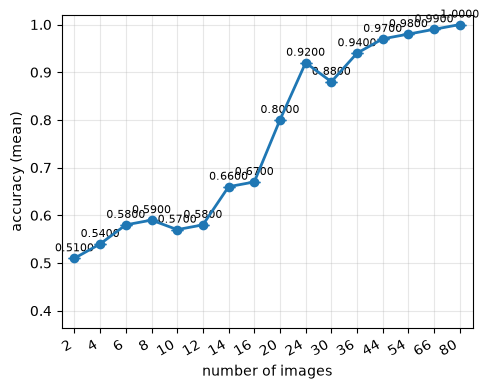

[np.float64(0.5100000023841857), np.float64(0.5399999976158142), np.float64(0.5799999952316284), np.float64(0.5900000095367431), np.float64(0.5700000107288361), np.float64(0.5799999952316284), np.float64(0.6600000143051148), np.float64(0.6700000047683716), np.float64(0.8), np.float64(0.9199999928474426), np.float64(0.8799999952316284), np.float64(0.9399999856948853), np.float64(0.9699999928474426), np.float64(0.9799999952316284), np.float64(0.9899999976158143), np.float64(1.0)]
['2', '4', '6', '8', '10', '12', '14', '16', '20', '24', '30', '36', '44', '54', '66', '80']


([np.float64(0.5100000023841857),
  np.float64(0.5399999976158142),
  np.float64(0.5799999952316284),
  np.float64(0.5900000095367431),
  np.float64(0.5700000107288361),
  np.float64(0.5799999952316284),
  np.float64(0.6600000143051148),
  np.float64(0.6700000047683716),
  np.float64(0.8),
  np.float64(0.9199999928474426),
  np.float64(0.8799999952316284),
  np.float64(0.9399999856948853),
  np.float64(0.9699999928474426),
  np.float64(0.9799999952316284),
  np.float64(0.9899999976158143),
  np.float64(1.0)],
 ['2',
  '4',
  '6',
  '8',
  '10',
  '12',
  '14',
  '16',
  '20',
  '24',
  '30',
  '36',
  '44',
  '54',
  '66',
  '80'])

In [9]:
learning_curve_cv(source, benchmark_output_dir, benchmark_output_csv, sizes)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


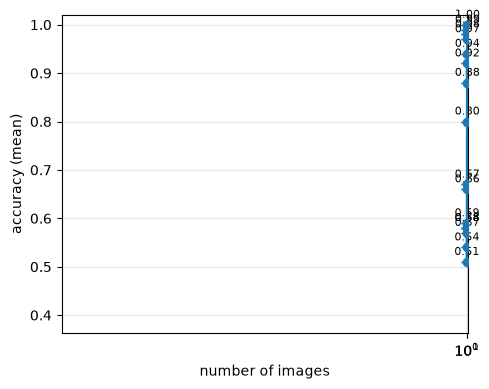

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


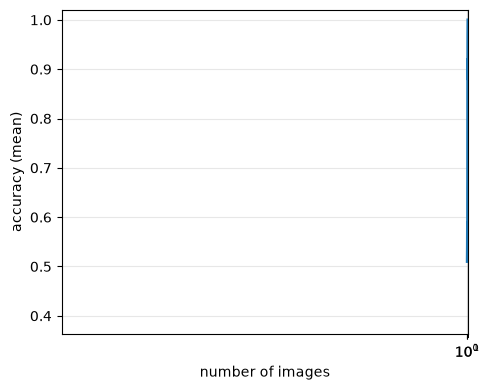

In [23]:
mesures = [np.float64(0.5100000023841857), np.float64(0.5399999976158142), np.float64(0.5799999952316284), np.float64(0.5900000095367431), np.float64(0.5700000107288361), np.float64(0.5799999952316284), np.float64(0.6600000143051148), np.float64(0.6700000047683716), np.float64(0.8), np.float64(0.9199999928474426), np.float64(0.8799999952316284), np.float64(0.9399999856948853), np.float64(0.9699999928474426), np.float64(0.9799999952316284), np.float64(0.9899999976158143), np.float64(1.0)]
names = [2, 4, 6, 8, 10, 12, 14, 16, 20, 24, 30, 36, 44, 54, 66, 80]

plot_metrics(mesures, names, metrics=[("accuracy", "number of images")], savename="articles/observation/learning_curve_points")
plot_metrics(mesures, names, metrics=[("accuracy", "number of images")], savename="articles/observation/learning_curve_no_points", show_points=False)